# Отображения элементов оператором потока Ли (`Bell.LieFlow`) против COSY INFINITY
Новый маршрут Bell: для s-независимого элемента берётся **полный** гамильтониан $H$ (точный корень $p_s$, кривизна, энергетический член)
как DA порядка $N+1$, и отображение вычисляется как сумма ряда Ли
$$\mathcal M = e^{-L{:}H{:}}z=\sum_n \frac{(-L)^n}{n!}{:}H{:}^n z=\sum_n\frac{L^n}{n!}(F\cdot\nabla)^n z,\qquad F=S\nabla H,$$
до машинной точности (`lie_flow_map(e, ref, N)`, кольцо — `one_turn_map_flow(lat, N)`). Старый маршрут Драгта–Финна (H до степени 4, карты порядка 3) не тронут.

Элементы (протон 200 МэВ, масса 938.27208816 МэВ как в Bell; COSY `RP 200 938.27208816/AMUMEV 1` вместо `RPP`; $\eta=K/mc^2$ и $B\rho$ из COSY `refpart.txt`): дрейф 0.5 м (`DL`), квадруполь 0.5 м, 0.5 Тл/0.05 м (`MQ`), секторный диполь
$R=2$ м, 30° (`MS`), секступоль 0.3 м, 0.2 Тл/0.05 м (`MH`); порядки 3, 5, 7, 10. COSY: `cosy/elem6_template.fox` (все 6 строк карты),
Bell: `julia/lie_flow_bench.jl`. В Bell $\delta=\Delta p/p_0$, в COSY $\delta_K$; карта Bell подставляется в $\delta(\delta_K)$ композицией, сравниваются строки $x,a,y,b$.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
acc = pd.read_csv('output/flow_vs_cosy.csv'); spd = pd.read_csv('output/flow_speed.csv'); sym = pd.read_csv('output/flow_symp.csv')
symL = pd.read_csv('output/flow_symp_L.csv'); ring = pd.read_csv('output/ring_df_vs_flow.csv')
wp = pd.read_csv('../da_integrators/output/ode_workprecision.csv')
acc['route'] = np.where(acc.row.astype(str).str.startswith('force'), 'сила z\'=f(z) (прототип)', 'LieFlow (H)')
EL = ['drift', 'quad', 'dipole', 'sext']

## 1. Совпадение коэффициентов с COSY

In [2]:
t = acc.groupby(['element', 'order', 'route']).rel.max().unstack(['route']); t.style.format('{:.1e}')

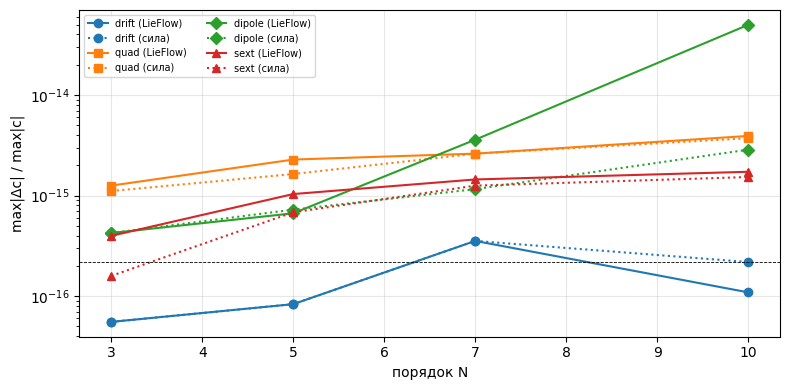

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
for el, m in zip(EL, 'osD^'):
    a = acc[(acc.element == el) & (acc.route == 'LieFlow (H)')].groupby('order').rel.max()
    ax.semilogy(a.index, a.values.clip(1e-17), m + '-', label=el + ' (LieFlow)')
    b = acc[(acc.element == el) & (acc.route != 'LieFlow (H)')].groupby('order').rel.max()
    ax.semilogy(b.index, b.values.clip(1e-17), m + ':', color=ax.lines[-1].get_color(), label=el + ' (сила)')
ax.axhline(2.2e-16, color='k', lw=.6, ls='--'); ax.set_xlabel('порядок N'); ax.set_ylabel('max|Δc| / max|c|'); ax.grid(alpha=.3); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig('fig_flow_vs_cosy.png', dpi=110); plt.show()

**Рисунок 1.** Относительное расхождение коэффициентов строк $x,a,y,b$ карт Bell и COSY по порядкам. Сплошные линии — новый маршрут
LieFlow (из гамильтониана, затем подстановка $\delta(\delta_K)$), пунктир — прототип «силовой» формы $z'=f(z)$ из `da_integrators`
(сразу в переменных COSY). Оба совпадают с COSY до округления: $\le 1.5\cdot10^{-15}$, кроме диполя при $N=10$ ($4\cdot10^{-14}$ —
ошибки округления в композиции с $\delta(\delta_K)$, у силовой формы без неё $2.6\cdot10^{-15}$).

## 2. Скорость

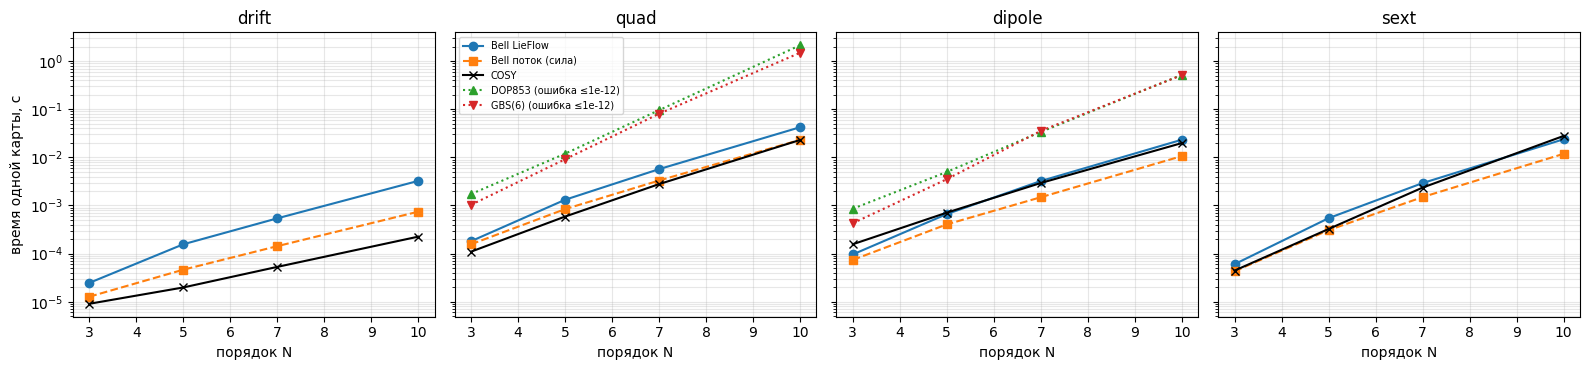

In [4]:
ref = []
for pr, el in (('quad', 'quad'), ('dipole', 'dipole')):
    for m in ('DOP853', 'GBS(6)'):
        a = wp[(wp.problem == pr) & (wp.method == m) & (wp.err_vs_ref <= 1e-12)].groupby('order').time_s.min()
        for o, t_ in a.items(): ref.append(dict(element=el, order=o, method=m, time_s=t_))
ref = pd.DataFrame(ref)
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, el in zip(axs, EL):
    s = spd[spd.element == el]
    ax.semilogy(s.order, s.bell_flow_s, 'o-', label='Bell LieFlow'); ax.semilogy(s.order, s.forceflow_s, 's--', label='Bell поток (сила)')
    ax.semilogy(s.order, s.cosy_s, 'kx-', label='COSY')
    for m, mk in (('DOP853', '^:'), ('GBS(6)', 'v:')):
        r = ref[(ref.element == el) & (ref.method == m)]
        if len(r): ax.semilogy(r.order, r.time_s, mk, label=m + ' (ошибка ≤1e-12)')
    ax.set_title(el); ax.set_xlabel('порядок N'); ax.grid(alpha=.3, which='both')
axs[0].set_ylabel('время одной карты, с'); axs[1].legend(fontsize=7); plt.tight_layout(); plt.savefig('fig_flow_speed.png', dpi=110); plt.show()
spd[['element', 'order', 'ratio_flow_cosy', 'ratio_force_cosy']].pivot(index='element', columns='order').style.format('{:.2f}').set_caption('Время Bell / время COSY')

**Рисунок 2.** Время вычисления одной карты элемента в зависимости от порядка: Bell LieFlow (6 строк, из $H$), прототип силовой формы
(4 строки, $\delta_K$ — параметр), COSY (`DL`/`MQ`/`MS`/`MH`), и для квадруполя/диполя — DOP853 и GBS(6) с DA-начальными условиями при ошибке
$\le10^{-12}$ (из `da_integrators`). LieFlow по сравнению с COSY: диполь 0.6–1.2, секступоль 0.9–1.5, квадруполь 1.5–2.1; дрейф в COSY
аналитический (`DLACT`) и в 3–15 раз быстрее. Относительно DOP853/GBS поток быстрее в 5–30 раз. Силовая форма ещё ~2 раза быстрее LieFlow:
она считает 4 строки вместо 6 (у LieFlow есть $l$) и без гамильтониана порядка $N+1$.

## 3. Симплектичность

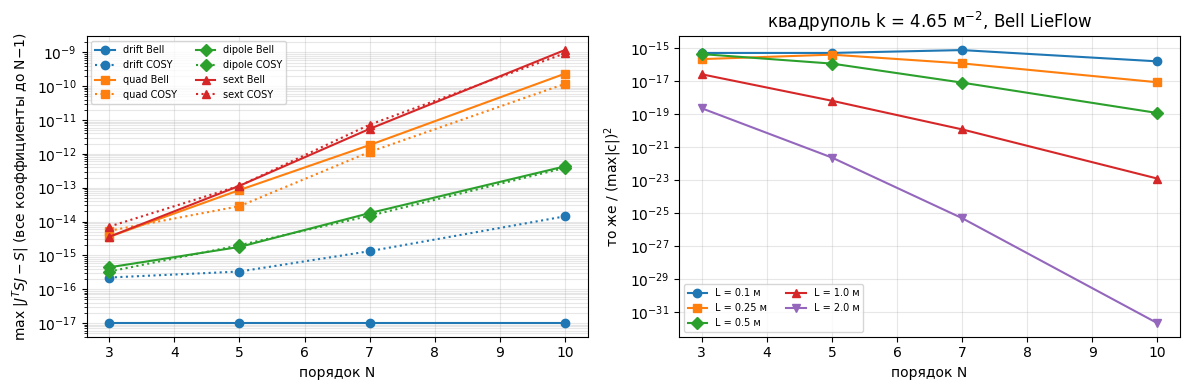

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for el, m in zip(EL, 'osD^'):
    s = sym[sym.element == el]
    ax[0].semilogy(s.order, s.bell_flow.clip(1e-17), m + '-', label=el + ' Bell'); ax[0].semilogy(s.order, s.cosy.clip(1e-17), m + ':', color=ax[0].lines[-1].get_color(), label=el + ' COSY')
for L, m in zip(sorted(symL.L.unique()), 'osD^v'):
    s = symL[symL.L == L]; ax[1].semilogy(s.order, s.symp_rel.clip(1e-35), m + '-', label=f'L = {L} м')
ax[0].set_ylabel(r'max $|J^TSJ-S|$ (все коэффициенты до N−1)'); ax[1].set_ylabel(r'то же / (max|c|)$^2$')
ax[1].set_title('квадруполь k = 4.65 м$^{-2}$, Bell LieFlow')
for a_ in ax: a_.set_xlabel('порядок N'); a_.grid(alpha=.3, which='both'); a_.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig('fig_flow_symp.png', dpi=110); plt.show()

**Рисунок 3.** Слева: ошибка симплектичности $J^TSJ-S$, где $J=\partial\mathcal M/\partial z$ — DA-матрица, по всем коэффициентам
до порядка $N-1$, для карт Bell LieFlow и COSY (карта COSY экспортирована полностью, 6×6, переменные $(x,a,y,b,l,\delta_K)$ — канонические).
Обе карты симплектичны до округления; абсолютная величина растёт вместе с коэффициентами высоких порядков (квадруполь, секступоль при $N=10$:
коэффициенты $\sim10^4$). Справа: та же ошибка, нормированная на квадрат наибольшего коэффициента, для квадруполя длины 0.1–2 м
(до $L\rho=9$, включается масштабирование и возведение в квадрат) — везде $\le 10^{-15}$.

## 4. Кольцо: Драгт–Финн (порядок 3) против потока

In [6]:
ring

,route,time_s,max_abs_diff_vs_DF_order3,symp_err,max_abs_coef_DF
0,flow N=3,0.241480,2.842000e-12,9.322000e-12,904.61
1,flow N=5 (truncated to 3),0.094999,2.842000e-12,6.548000e-10,904.61
2,flow N=7 (truncated to 3),0.518560,2.842000e-12,3.912000e-08,904.61
3,Lie maps composed (compose_maps),0.036556,5.002000e-12,5.684000e-12,904.61
4,Dragt-Finn factor_to_map(ring_lie_factor),4.340400,0.000000e+00,9.322000e-12,904.61


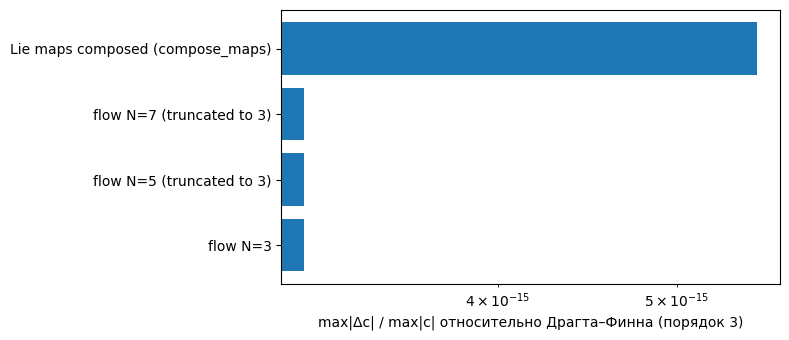

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
r = ring[ring.route != 'Dragt-Finn factor_to_map(ring_lie_factor)']
ax.barh(r.route, r.max_abs_diff_vs_DF_order3 / r.max_abs_coef_DF); ax.set_xscale('log'); ax.set_xlabel('max|Δc| / max|c| относительно Драгта–Финна (порядок 3)')
ax.grid(alpha=.3, axis='x'); plt.tight_layout(); plt.savefig('fig_ring_df.png', dpi=110); plt.show()

**Рисунок 4.** Кольцо `magnetic_2_md` (без ВЧ): коэффициенты порядков 0–3 однооборотной карты по разным маршрутам относительно
`factor_to_map(ring_lie_factor(lat))` (Драгт–Финн). Поток порядка 3, 5 и 7 (обрезанный до 3) и композиция старых отображений Ли совпадают с
Драгтом–Финном до $\sim10^{-14}$ относительно (абс. $10^{-11}$ при коэффициентах ~900): старый маршрут точен в своём порядке 3, новый
воспроизводит его и даёт произвольный порядок. Время: Драгт–Финн 3.8 с, поток $N=3$ 0.3 с, $N=7$ 0.55 с (кэшировано по элементам).
Хроматичность кольца по потоку пока не считалась — по договорённости.

## 5. Выводы
* **Точность:** LieFlow = COSY до $\le1.5\cdot10^{-15}$ относительно (диполь $N=10$: $4\cdot10^{-14}$) для дрейфа, квадруполя, диполя, секступоля, $N=3..10$;
  на порядке 3 совпадает со старым маршрутом Ли до $10^{-15}$; кольцо — с Драгтом–Финном до $10^{-14}$.
* **Симплектичность:** $J^TSJ-S$ на уровне округления у Bell и у COSY на всех порядках (относительно $\le10^{-15}$).
* **Скорость (Bell/COSY):** диполь 0.6–1.2, секступоль 0.9–1.5, квадруполь 1.5–2.1, дрейф 3–15 (COSY: аналитический дрейф).
  Против DOP853/GBS — в 5–30 раз быстрее при машинной точности.
* **Что ещё можно ускорить:** аналитический дрейф (как `DLACT`), считать строку $l$ только по требованию, суммировать ряд одновременно для всех строк
  (общие произведения $F_i\,\partial_i$), in-place сложение членов ряда.